# 19 · The Bayesian evidence: ln Z without nested sampling

**Level:** intermediate · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb); [12](12_importance_sampling_from_scratch.ipynb) helps · **Run time:** ~30 min (~4 min with `PIZZETTI_SMOKE=1`), nearly all of it dynesty

**Covers:** `lnz` and `lnz_err` of `profile_is` and `fit`; what goes into them; a comparison with the nested sampler [dynesty](https://dynesty.readthedocs.io), with and without the marginal likelihood; accuracy against cost; a grazing transit; a Bayes factor for "is there a transit?"; how the prior enters; when not to trust the number

The evidence is the probability of the data under a model, averaged over its prior:

$$Z = \int \mathcal{L}(\boldsymbol{y}\,|\,\boldsymbol{\theta})\,\pi(\boldsymbol{\theta})\,d\boldsymbol{\theta} .$$

The ratio of two evidences is the Bayes factor between two models. Nested sampling is the usual way to compute Z, at the
price of millions of likelihood calls. Importance sampling gets it for free: with a normalised proposal $q$, the mean of
the raw weights $p/q$ *is* the integral of $p$. pizzetti does this on every call of `profile_is`.

Dynesty is only needed for the comparison in this notebook (`pip install dynesty`).

In [1]:
import math
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import dynesty
import pizzetti

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"
warnings.filterwarnings("ignore", category=RuntimeWarning)

PER, A = 3.5, 9.0
U_TRUE = [0.40, 0.25]
T_ONE = np.arange(-0.13, 0.13, 2.0 / 1440)
TIMES = (np.arange(7)[:, None] * PER + T_ONE[None, :]).ravel()
WIDE = dict(t0=(-0.05, 0.05), rp=(1e-4, 0.5), a=(1.5, 30.0))      # the prior: finite bounds on every free parameter


def simulate(rp, b, sigma, seed=42):
    # seven transits at 2-min cadence, as in notebooks 02-06 and 14
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = 0.0, PER, rp, A
    p.inc = np.degrees(np.arccos(b / A))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", list(U_TRUE)
    y = pizzetti.TransitModel(p, TIMES).light_curve(p) + sigma * np.random.default_rng(seed).standard_normal(TIMES.size)
    return p, y


def make_model(p, y, sigma, box=WIDE):
    return pizzetti.MarginalTransitModel(p, TIMES, y, sigma, free=("t0", "rp", "a", "b"), bounds=box)


SIGMA = 500e-6
p, y = simulate(rp=0.10, b=0.35, sigma=SIGMA)
model = make_model(p, y, SIGMA)
print(len(y), "points, free:", model.free)

1316 points, free: ['t0', 'rp', 'a', 'b']


## 1. One call

`profile_is` returns the ln evidence and its Monte Carlo error. `fit()` puts them in `diagnostics`. Nothing has to be switched on.

In [2]:
t_start = time.perf_counter()
res = model.profile_is(n=4000, rng=np.random.default_rng(1))
print(f"ln Z = {res['lnz']:.3f} +- {res['lnz_err']:.3f}   ({res['n_eval']} evaluations, {time.perf_counter() - t_start:.1f} s, "
      f"k-hat {res['khat']:.2f}, usable {res['is_ok']})")

d = model.fit(seed=1, n=4000).diagnostics
print(f"fit():  {d['lnz']:.3f} +- {d['lnz_err']:.3f}")

ln Z = 8107.699 +- 0.010   (12128 evaluations, 1.0 s, k-hat -0.05, usable True)


fit():  8107.699 +- 0.010


**Two conventions.** The prior is uniform over `bounds` and over the limb-darkening parameters $(q_1, q_2)$. The flat prior on the baseline
$f_0$ has unit density, so for a flat $f_0$ in a box of width $\Delta f_0$, subtract $\ln\Delta f_0$. (It cancels between two models with the same baseline
prior, as in section 6.)

An evidence needs a proper prior, so it needs **finite bounds**. By default `per` and `a` have no upper bound. Then there is
no evidence to report: `lnz` is nan, and `lnz_note` says why. `log_int`, the bare integral of the log posterior, is always there.

In [3]:
unbounded = pizzetti.MarginalTransitModel(p, TIMES, y, SIGMA, free=("t0", "rp", "a", "b"), bounds={"t0": (-0.05, 0.05), "rp": (1e-4, 0.5)})
r = unbounded.profile_is(n=1000, rng=np.random.default_rng(1))
print("lnz:", r["lnz"], "|", r["lnz_note"])
print(f"log_int: {r['log_int']:.3f}")

lnz: nan | lnz needs finite bounds on every free parameter (and an upper bound on rp and a)
log_int: -688.073


## 2. What goes into the number

The likelihood that `profile_is` samples has limb darkening and baseline integrated out (notebook 06), up to constants that a posterior
does not need and an evidence does. Four pieces make up ln Z:

$$\ln Z = \underbrace{\ln\left\langle \frac{p}{q}\right\rangle}_{\text{log\_int}}
+ \underbrace{\left[-\frac{N-3}{2}\ln 2\pi - \sum_i \ln\sigma_i\right]}_{\text{Gaussian constants}}
- \underbrace{\ln V}_{\text{prior volume}}
+ \underbrace{\ln\left\langle \frac{f_0}{c_2^3}\right\rangle + \ln 2}_{\text{limb-darkening prior}}$$

- **`log_int`** is the mean of the raw weights. No Pareto smoothing here: it stabilises normalised weights but biases their mean.
- The **Gaussian constants** are the ones dropped from the likelihood, with the $(2\pi)^{3/2}$ of the integral over the three coefficients.
- $V$ is the volume of the geometry prior. Since $0 \le b < 1 + R_p/R_\star$, it is $\Delta t_0\,\Delta a \int (1 + r)\,dr$ here.
- The last term turns the flat prior over the cone of coefficients into Kipping's uniform $(q_1, q_2)$: the mean of the weight $f_0/c_2^3$ of the paper's Eq. 8 over the joint posterior, and 2 for the density on the triangle of area 1/2. It needs no extra likelihood calls beyond the conditional limb-darkening draws.

Rebuilt by hand:

In [4]:
def ln_ld_term(m, theta, weights, seed=0):
    # ln <f0 / c2^3> + ln 2 from conditional limb-darkening draws at weighted geometry draws
    pos = weights > 0
    S, lab, _ = m.expand(m.to_physical(theta[pos]), ld="u", rng=np.random.default_rng(seed), resample=False)
    u1, u2, f0 = S[:, lab.index("u1")], S[:, lab.index("u2")], S[:, lab.index("f0")]
    c2 = f0 / ((1 - u1 - u2) / 6 + (1 - 0.5 * u1) / 3 + 0.5)
    lw = np.log(f0) - 3 * np.log(c2)
    return logsumexp(lw, b=weights[pos] / weights[pos].sum()) + math.log(2.0)


def ln_constants(sigma, n):
    return -0.5 * (n - 3) * math.log(2 * math.pi) - n * math.log(sigma)


def ln_volume(box):
    r0, r1 = box["rp"]
    return (math.log(box["t0"][1] - box["t0"][0]) + math.log(box["a"][1] - box["a"][0])
            + math.log((r1 - r0) + 0.5 * (r1 ** 2 - r0 ** 2)))


pieces = dict(log_int=res["log_int"], constants=ln_constants(SIGMA, len(y)), minus_ln_V=-ln_volume(WIDE),
              ld=ln_ld_term(model, res["theta"], res["w"]))
for name, v in pieces.items():
    print(f"{name:12s} {v:12.3f}")
print(f"{'sum':12s} {sum(pieces.values()):12.3f}")
print(f"{'res[lnz]':12s} {res['lnz']:12.3f} +- {res['lnz_err']:.3f}")

log_int          -688.052
constants        8796.221
minus_ln_V         -0.577
ld                  0.107
sum              8107.699
res[lnz]         8107.699 +- 0.010


## 3. Against dynesty

Two nested-sampling runs on the same prior, with a box $f_0 \in (0.99, 1.01)$:

- **marginal**: dynesty over the four geometry parameters on `model.log_prob`, the same integrand as importance sampling, integrated another way.
- **conventional**: dynesty over seven parameters, $(t_0, R_p/R_\star, a/R_\star, b, q_1, q_2, f_0)$, on the plain Gaussian likelihood of `TransitModel`. No marginalisation at all, so this also tests the integral over the cone and every constant above.

`rslice` is dynesty's choice for curved posteriors at this dimension.

In [5]:
F0_BOX = (0.99, 1.01)
LN_F0 = math.log(F0_BOX[1] - F0_BOX[0])
NLIVE = 100 if SMOKE else 500


def is_lnz(m, seed, n=4000):
    # with the flat f0 box of the conventional fit
    t1 = time.perf_counter()
    r = m.profile_is(n=n, rng=np.random.default_rng(seed))
    return dict(lnz=r["lnz"] - LN_F0, err=r["lnz_err"], evals=r["n_eval"], wall=time.perf_counter() - t1, ok=r["is_ok"], res=r)


def nested_marginal(m, box, sigma, n_pts, nlive=NLIVE, seed=1):
    lo = np.array([box["t0"][0], box["rp"][0], box["a"][0], 0.0])
    hi = np.array([box["t0"][1], box["rp"][1], box["a"][1], 1.0 + box["rp"][1]])

    def loglike(x):
        if x[3] >= 1 + x[1]:                  # outside the prior; the cube is larger than its support
            return -1e300
        v = m.log_prob(x)
        return v if v > -1e299 else -1e300
    t1 = time.perf_counter()
    s = dynesty.NestedSampler(loglike, lambda u: lo + u * (hi - lo), 4, nlive=nlive, sample="rslice", slices=10,
                              rstate=np.random.default_rng(seed))
    s.run_nested(dlogz=0.01, print_progress=False)
    r = s.results
    log_int = r.logz[-1] + np.sum(np.log(hi - lo))
    w = np.exp(r.logwt - logsumexp(r.logwt))
    j = np.random.default_rng(seed).choice(len(w), 4000, p=w)
    Xi = m.to_internal(r.samples[j])
    ld = ln_ld_term(m, Xi, np.full(len(j), 1.0 / len(j)), seed=seed)
    lnz = log_int + ln_constants(sigma, n_pts) - ln_volume(box) + ld - LN_F0
    return dict(lnz=float(lnz), err=float(r.logzerr[-1]), evals=int(np.sum(r.ncall)), wall=time.perf_counter() - t1, samples=r.samples, w=w,
                info=float(r.information[-1]))


def nested_conventional(p, y, sigma, box, nlive=NLIVE, seed=1):
    tm = pizzetti.TransitModel(p, TIMES)
    q = pizzetti.TransitParams()
    q.per, q.ecc, q.w, q.limb_dark = PER, 0.0, 90.0, "quadratic"
    lo = np.array([box["t0"][0], box["rp"][0], box["a"][0], 0.0, 0.0, 0.0, F0_BOX[0]])
    hi = np.array([box["t0"][1], box["rp"][1], box["a"][1], 1.0 + box["rp"][1], 1.0, 1.0, F0_BOX[1]])
    const = -0.5 * y.size * math.log(2 * math.pi) - y.size * math.log(sigma)

    def loglike(x):
        if x[3] >= 1 + x[1]:
            return -1e300
        q.t0, q.rp, q.a = x[0], x[1], x[2]
        q.inc = math.degrees(math.acos(x[3] / x[2]))
        sq = math.sqrt(x[4])
        q.u = [2 * sq * x[5], sq * (1 - 2 * x[5])]
        d = (y - x[6] * tm.light_curve(q)) / sigma
        return const - 0.5 * float(d @ d)
    t1 = time.perf_counter()
    s = dynesty.NestedSampler(loglike, lambda u: lo + u * (hi - lo), 7, nlive=nlive, sample="rslice", slices=14,
                              rstate=np.random.default_rng(seed))
    s.run_nested(dlogz=0.01, print_progress=False)
    r = s.results
    # the cube's geometry has L = 0 at b >= 1 + rp, so only the volume changes; q1, q2, f0 are the prior already
    lnz = r.logz[-1] + np.sum(np.log(hi[:4] - lo[:4])) - ln_volume(box)
    return dict(lnz=float(lnz), err=float(r.logzerr[-1]), evals=int(np.sum(r.ncall)), wall=time.perf_counter() - t1,
                samples=r.samples, w=np.exp(r.logwt - logsumexp(r.logwt)))


def compare(p, y, sigma, m, box, n_is, n_ns):
    out = dict(IS=[is_lnz(m, s) for s in range(1, n_is + 1)],
               marginal=[nested_marginal(m, box, sigma, y.size, seed=s) for s in range(1, n_ns + 1)],
               conventional=[nested_conventional(p, y, sigma, box, seed=s) for s in range(1, n_ns + 1)])
    for k, rows in out.items():
        print(f"{k:13s} ln Z " + "  ".join(f"{r['lnz']:.3f}+-{r['err']:.3f}" for r in rows)
              + f"   evaluations ~{int(np.median([r['evals'] for r in rows]))}, ~{np.median([r['wall'] for r in rows]):.0f} s each")
    return out


easy = compare(p, y, SIGMA, model, WIDE, n_is=2 if SMOKE else 5, n_ns=1 if SMOKE else 2)

IS            ln Z 8111.611+-0.010  8111.596+-0.010  8111.612+-0.010  8111.595+-0.010  8111.594+-0.010   evaluations ~12128, ~1 s each
marginal      ln Z 8111.558+-0.205  8111.563+-0.205   evaluations ~649270, ~109 s each
conventional  ln Z 8111.883+-0.253  8111.537+-0.254   evaluations ~1410135, ~90 s each


## 4. A grazing transit

Importance sampling has to work harder on a grazing transit, where a long ridge in $(b, R_p/R_\star)$ runs up to the prior bound (notebook 15).
The evidence comes along with whatever it takes to get usable draws.

In [6]:
p_g, y_g = simulate(rp=0.103, b=1.0, sigma=SIGMA)
model_g = make_model(p_g, y_g, SIGMA)
grazing = compare(p_g, y_g, SIGMA, model_g, WIDE, n_is=2 if SMOKE else 3, n_ns=1 if SMOKE else 2)
if not SMOKE:                              # more live points: see below
    grazing["conventional_1500"] = [nested_conventional(p_g, y_g, SIGMA, WIDE, nlive=1500, seed=11)]
    grazing["marginal_1500"] = [nested_marginal(model_g, WIDE, SIGMA, y_g.size, nlive=1500, seed=12)]
    for k in ("marginal_1500", "conventional_1500"):
        r = grazing[k][0]
        print(f"{k}: ln Z {r['lnz']:.3f}+-{r['err']:.3f}, {r['evals']} evaluations, {r['wall']:.0f} s")
print("usable:", [r["ok"] for r in grazing["IS"]])
print(f"information H of the two posteriors: {easy['marginal'][0]['info']:.1f} and {grazing['marginal'][0]['info']:.1f} nats")

IS            ln Z 8121.796+-0.018  8121.765+-0.017  8121.784+-0.017   evaluations ~74883, ~11 s each
marginal      ln Z 8121.554+-0.163  8122.001+-0.162   evaluations ~494334, ~53 s each
conventional  ln Z 8121.247+-0.216  8120.725+-0.218   evaluations ~1244028, ~62 s each


marginal_1500: ln Z 8121.799+-0.094, 1479460 evaluations, 291 s
conventional_1500: ln Z 8121.699+-0.124, 3528773 evaluations, 185 s
usable: [True, True, True]
information H of the two posteriors: 19.9 and 12.5 nats


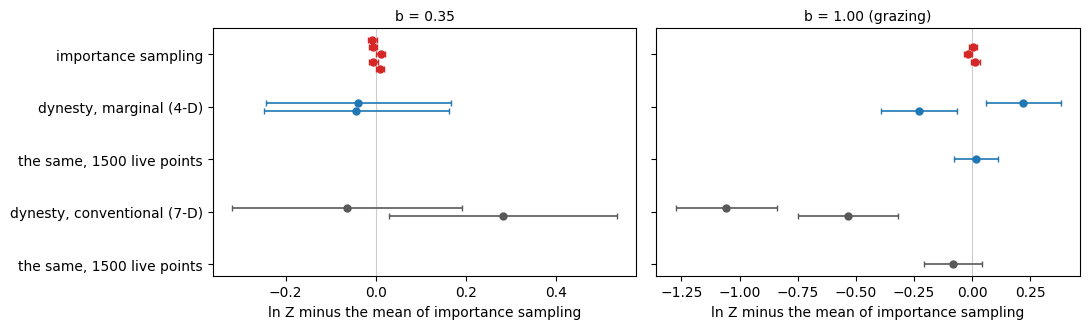

In [7]:
METHODS = [("IS", "importance sampling", "C3"), ("marginal", "dynesty, marginal (4-D)", "C0"), ("marginal_1500", "the same, 1500 live points", "C0"),
           ("conventional", "dynesty, conventional (7-D)", "0.35"), ("conventional_1500", "the same, 1500 live points", "0.35")]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, res_set, title in ((axes[0], easy, "b = 0.35"), (axes[1], grazing, "b = 1.00 (grazing)")):
    ref = np.mean([r["lnz"] for r in res_set["IS"]])
    for row, (k, label, col) in enumerate(METHODS):
        rows = res_set.get(k, [])
        for j, r in enumerate(rows):
            yy = len(METHODS) - 1 - row + (j - 0.5 * (len(rows) - 1)) * 0.14
            ax.errorbar(r["lnz"] - ref, yy, xerr=r["err"], fmt="o", ms=5, color=col, capsize=2, lw=1.2)
    ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    ax.set_xlabel("ln Z minus the mean of importance sampling")
    ax.set_title(title, fontsize=10)
axes[0].set_yticks(range(len(METHODS)))
axes[0].set_yticklabels([m[1] for m in METHODS][::-1])
fig.tight_layout()

Each point has the error its own method reports: that of importance sampling is the Monte Carlo error of the mean weight, that of dynesty its estimate from
the shrinkage of the prior volume. The conventional runs share nothing with the marginal likelihood but the light-curve model, so agreement also confirms the
integral over the cone and the constants.

On the easy posterior the methods agree within those errors. On the grazing ridge, dynesty with 500 live points scatters by more than it reports, and in seven dimensions it
comes out low: the ridge is thin, and a few hundred live points can lose part of it on the way up. With 1500 live points it agrees with importance sampling. So a reported error from nested
sampling is a lower limit where the posterior is hard, and the way to check it is what we did here: more live points, and more than one run.

The posteriors agree too. Here is the grazing transit under Kipping's prior, from `fit()` and from the 4-D dynesty run with the same limb-darkening weight:

P(b < 0.8): importance sampling 0.023, dynesty 0.028


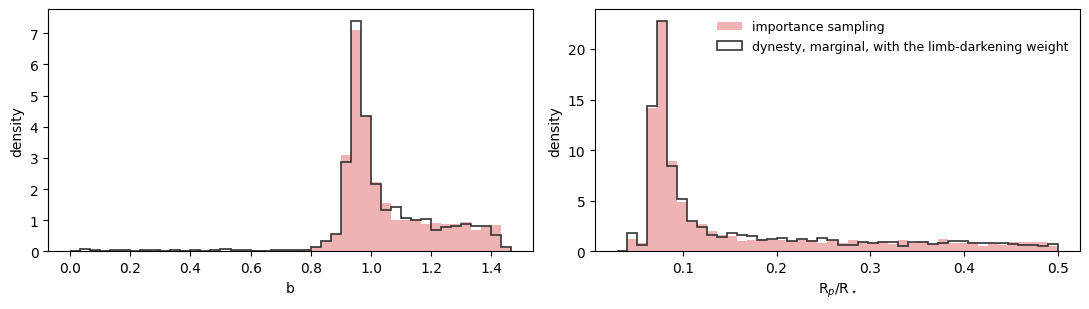

In [8]:
fit_g = model_g.fit(seed=1, n=4000)
cols = {n: j for j, n in enumerate(fit_g.labels)}
ns = grazing.get("marginal_1500", grazing["marginal"])[0]
pick = np.random.default_rng(1).choice(len(ns["w"]), 20000, p=ns["w"])
S_ns, lab_ns, w_ns = model_g.expand(ns["samples"][pick], ld="q", rng=np.random.default_rng(2), resample=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, name, label in ((axes[0], "b", "b"), (axes[1], "rp", "R$_p$/R$_\\star$")):
    x = fit_g.weighted_samples[:, cols[name]]
    bins = np.linspace(np.min(x), np.max(x), 45)
    ax.hist(x, bins=bins, weights=fit_g.weights, density=True, histtype="stepfilled", color="C3", alpha=0.35, label="importance sampling")
    ax.hist(S_ns[:, lab_ns.index(name)], bins=bins, weights=w_ns, density=True, histtype="step", color="0.2", lw=1.2, label="dynesty, marginal, with the limb-darkening weight")
    ax.set_xlabel(label)
    ax.set_ylabel("density")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()

low = fit_g.weighted_samples[:, cols["b"]] < 0.8
print(f"P(b < 0.8): importance sampling {np.sum(fit_g.weights[low]) / np.sum(fit_g.weights):.3f}, "
      f"dynesty {np.sum(w_ns[S_ns[:, lab_ns.index('b')] < 0.8]) / np.sum(w_ns):.3f}")

The small branch at b < 0.8 is a planet with extreme limb darkening, in a thin corner of $(q_1, q_2)$. There the conventional seven-parameter fit struggles most: four dynesty runs with 1500 live points on this light curve put 0.6, 1.1, 1.8 and 9.9% of the posterior at b < 0.8. That is what integrating the limb darkening exactly buys, whichever sampler you use.

## 5. Accuracy against cost

How many evaluations does a given accuracy take? The reference is the mean of the runs with the most evaluations. Importance sampling has a fixed entry
price, the profile of the proposal (about 8000 evaluations here); after that its error falls as one over the square root of the number of draws. Nested sampling's
error falls with the number of live points, $\propto\sqrt{H/n_{\rm live}}$, where the information $H$ is the shrinkage from prior to posterior (printed in section 4: about 20 nats here),
and its cost grows with $n_{\rm live} H$.

IS, n =    500:      8278 evaluations, reported error 0.028, ln Z - reference -0.031 +0.002 +0.029
IS, n =   1000:      8828 evaluations, reported error 0.019, ln Z - reference +0.013 +0.007 +0.018
IS, n =   2000:      9928 evaluations, reported error 0.014, ln Z - reference -0.022 -0.011 -0.011
IS, n =   4000:     12128 evaluations, reported error 0.010, ln Z - reference +0.013 -0.008 +0.010
IS, n =   8000:     16528 evaluations, reported error 0.007, ln Z - reference +0.000 +0.004 +0.002
IS, n =  16000:     25328 evaluations, reported error 0.005, ln Z - reference -0.006 -0.001 -0.004
IS, n =  32000:     42928 evaluations, reported error 0.003, ln Z - reference -0.002 -0.001 +0.003
dynesty, nlive =     50:     65660 evaluations, reported error 0.635, ln Z - reference -0.673 +1.097
dynesty, nlive =    100:    128870 evaluations, reported error 0.449, ln Z - reference +0.746 +0.291
dynesty, nlive =    200:    266368 evaluations, reported error 0.326, ln Z - reference -0.406 -0.447
dyne

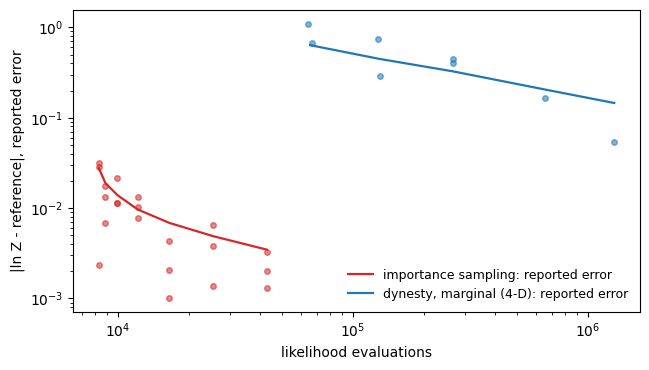

In [9]:
ns_grid = [100] if SMOKE else [50, 100, 200, 500, 1000]
is_grid = [500, 2000] if SMOKE else [500, 1000, 2000, 4000, 8000, 16000, 32000]
repeats = 1 if SMOKE else 3

curve_is = [[is_lnz(model, 100 * k + s, n=n) for s in range(repeats)] for k, n in enumerate(is_grid)]
curve_ns = [[nested_marginal(model, WIDE, SIGMA, y.size, nlive=nl, seed=200 + s) for s in range(1 if nl >= 500 else 2)] for nl in ns_grid]

ref = np.mean([r["lnz"] for r in curve_is[-1]])
for label, curve, grid in (("IS, n", curve_is, is_grid), ("dynesty, nlive", curve_ns, ns_grid)):
    for g, rows_ in zip(grid, curve):
        print(f"{label} = {g:6d}: {np.mean([r['evals'] for r in rows_]):9.0f} evaluations, reported error {np.mean([r['err'] for r in rows_]):.3f}, "
              f"ln Z - reference " + " ".join(f"{r['lnz'] - ref:+.3f}" for r in rows_))
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for curve, col, label in ((curve_is, "C3", "importance sampling"), (curve_ns, "C0", "dynesty, marginal (4-D)")):
    ev, dz = [], []
    for rows in curve:
        for r in rows:
            ev.append(r["evals"])
            dz.append(max(abs(r["lnz"] - ref), 1e-3))
    means = [(np.mean([r["evals"] for r in rows]), np.mean([r["err"] for r in rows])) for rows in curve]
    ax.plot(ev, dz, "o", ms=4, color=col, alpha=0.55)
    ax.plot(*zip(*means), "-", color=col, lw=1.6, label=label + ": reported error")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("likelihood evaluations")
ax.set_ylabel("|ln Z - reference|, reported error")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

On this easy posterior, both methods' reported errors describe their scatter. Importance sampling reaches 0.01 nats where dynesty, at about a hundred times the evaluations, reports about 0.15.
Dynesty is not doing anything wrong: this is a light curve whose posterior a proposal fits well, while nested sampling has to climb the whole way from the prior. That
climb is also its strength: it needs no proposal, and it finds modes that no proposal started near. See section 7.

## 6. Is there a transit? A Bayes factor

The alternative is a flat light curve with the same flat baseline, whose evidence is a one-dimensional Gaussian integral:

$$\ln Z_0 = -\frac{N}{2}\ln 2\pi - \sum_i \ln\sigma_i - \frac{\chi^2_{\min}}{2} + \frac{1}{2}\ln\frac{2\pi}{\sum_i\sigma_i^{-2}} .$$

Both models have unit density in $f_0$, so that convention cancels in $\ln B = \ln Z - \ln Z_0$. We inject transits of growing depth into 1000 ppm noise. Since ephemeris
priors are part of the model, we try two priors on the same data: a narrow one, as after a search that has located the signal, and a wide one.

In [10]:
def ln_z_null(y, sigma):
    chi2 = np.sum(((y - np.mean(y)) / sigma) ** 2)
    return (-0.5 * y.size * math.log(2 * math.pi) - y.size * math.log(sigma) - 0.5 * chi2
            + 0.5 * math.log(2 * math.pi * sigma ** 2 / y.size))


NARROW = dict(t0=(-0.01, 0.01), rp=(1e-3, 0.2), a=(5.0, 15.0))
SIG_B = 1000e-6
rp_grid = [0.015, 0.03] if SMOKE else [0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04]
rows = []
for rp in rp_grid:
    pb, yb = simulate(rp=rp, b=0.3, sigma=SIG_B, seed=7)
    snr = rp ** 2 / SIG_B * math.sqrt(np.sum(np.abs(T_ONE) < 0.065) * 7)
    row = dict(rp=rp, snr=snr)
    for key, box in (("narrow", NARROW), ("wide", WIDE)):
        pb_box = pb
        m = make_model(pb_box, yb, SIG_B, box)
        r = m.profile_is(n=4000, rng=np.random.default_rng(1))
        row[key] = (r["lnz"] - ln_z_null(yb, SIG_B), r["lnz_err"], bool(r["is_ok"]), int(r["n_eval"]))
    rows.append(row)
    print(f"rp {rp:.3f} S/N {snr:5.1f}  " + "  ".join(
        f"{k}: ln B {row[k][0]:8.2f} +- {row[k][1]:.2f} usable {row[k][2]} ({row[k][3]} evals)" for k in ("narrow", "wide")))

rp 0.005 S/N   0.6  narrow: ln B    -2.12 +- 0.02 usable True (50261 evals)  wide: ln B    -2.79 +- 0.02 usable True (89212 evals)


rp 0.010 S/N   2.6  narrow: ln B    -0.68 +- 0.02 usable True (61755 evals)  wide: ln B      nan +- nan usable False (1331 evals)


rp 0.015 S/N   5.8  narrow: ln B     6.03 +- 0.02 usable True (64639 evals)  wide: ln B     3.90 +- 0.02 usable True (83255 evals)


rp 0.020 S/N  10.3  narrow: ln B    26.35 +- 0.01 usable True (49571 evals)  wide: ln B    23.10 +- 0.02 usable True (76566 evals)


rp 0.025 S/N  16.0  narrow: ln B    69.84 +- 0.01 usable True (44343 evals)  wide: ln B    66.29 +- 0.01 usable True (47996 evals)


rp 0.030 S/N  23.1  narrow: ln B   149.42 +- 0.01 usable True (48350 evals)  wide: ln B   145.79 +- 0.01 usable True (51423 evals)


rp 0.040 S/N  41.0  narrow: ln B   480.98 +- 0.01 usable True (57164 evals)  wide: ln B   477.29 +- 0.01 usable True (12325 evals)


Is the importance-sampling number right at such a low signal-to-noise ratio? Dynesty on the narrow prior, where it starts from the prior rather than from a maximum:

In [11]:
for rp in ([0.015] if SMOKE else [0.005, 0.015]):
    pb, yb = simulate(rp=rp, b=0.3, sigma=SIG_B, seed=7)
    m = make_model(pb, yb, SIG_B, NARROW)
    ns = nested_marginal(m, NARROW, SIG_B, yb.size)
    row = next(r for r in rows if r["rp"] == rp)
    print(f"rp {rp:.3f}: dynesty ln B {ns['lnz'] + LN_F0 - ln_z_null(yb, SIG_B):.2f} +- {ns['err']:.2f}, importance sampling {row['narrow'][0]:.2f} +- {row['narrow'][1]:.2f}")

rp 0.005: dynesty ln B -2.11 +- 0.08, importance sampling -2.12 +- 0.02


rp 0.015: dynesty ln B 6.11 +- 0.09, importance sampling 6.03 +- 0.02


Occam penalty of the wide prior, mean over the clear detections: 3.53 nats (expected from the volumes alone: 3.71)


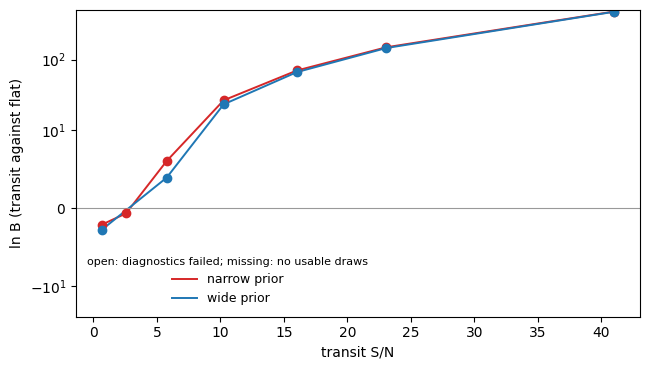

In [12]:
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for key, col, label in (("narrow", "C3", "narrow prior"), ("wide", "C0", "wide prior")):
    good = [r for r in rows if np.isfinite(r[key][0])]
    ax.plot([r["snr"] for r in good], [r[key][0] for r in good], "-", color=col, lw=1.4, label=label)
    for r in good:
        ok = r[key][2]
        ax.errorbar(r["snr"], r[key][0], yerr=r[key][1], fmt="o", ms=6, color=col, mfc=col if ok else "white", capsize=2)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("transit S/N")
ax.set_ylabel("ln B (transit against flat)")
ax.legend(frameon=False, fontsize=9, title="open: diagnostics failed; missing: no usable draws", title_fontsize=8)
fig.tight_layout()

gap = np.mean([r["narrow"][0] - r["wide"][0] for r in rows if r["narrow"][2] and r["wide"][2] and r["snr"] > 8])
print(f"Occam penalty of the wide prior, mean over the clear detections: {gap:.2f} nats (expected from the volumes alone: "
      f"{ln_volume(WIDE) - ln_volume(NARROW):.2f})")

Three things to read off.

- **The evidence depends on the prior.** The same data score lower under the wide prior, by about the ratio of the prior volumes, once the data have left the likelihood well inside both boxes. This is the Occam penalty, and it is the point of Z, not a defect. But a Bayes factor means nothing without its prior, so state your `bounds`.
- **A shallow signal is a hard posterior.** With no transit to pin it down, the posterior fills the box, and a proposal built around one maximum has little to hold on to. Look at `is_ok` for every point: a run that fails its diagnostics is drawn open, and one with no usable draws has `lnz` nan and is not drawn at all. Do not use those. Where the draws pass, dynesty agrees, as the check above shows, down to S/N < 1.
- **This is not a false-alarm rate.** It compares two models at a known location. A search over period and phase has a look-elsewhere effect that this prior does not include unless the prior is as wide as the search.

## 7. When not to trust the number

| Situation | What to do |
|---|---|
| `is_ok` False | Don't use `lnz`. `lnz_err` is only meaningful for k̂ < 0.7. |
| A second mode that no draw reached | `lnz` is too low by the missing mass, and `lnz_err` cannot know. `profile_is` searches along b only, so a period alias or a second transit time is not covered. Compare each mode's evidence with a run per mode, or use nested sampling. |
| `lnz` is nan | Read `lnz_note`: an infinite bound, a `log_prior`, a Gaussian or callable `ld_prior`, `gp`, a free `ecc` or `w`, or a law other than quadratic. `log_int` is still valid, and ratios between runs with the same unnormalised prior are valid too. |
| Comparing models with different baselines | Add the $-\ln\Delta f_0$ of each by hand. |

## What you learned

- `profile_is` and `fit` return `lnz` and `lnz_err`, for finite bounds, from the raw importance weights.
- It is the mean weight plus the Gaussian constants, the prior volume and the limb-darkening prior.
- It agrees with dynesty, both on the marginal likelihood and on the conventional seven-parameter fit, at a small fraction of the evaluations and with a smaller error, as long as the draws pass their diagnostics.
- A Bayes factor against a flat light curve takes one extra line, and it depends on the prior, as it must.

**Next:** [the theory](https://pizzetti.readthedocs.io/en/latest/marginal.html), [tutorial 15](15_when_the_profile_is_not_enough.ipynb) for hard posteriors, [tutorial 16](16_is_against_mcmc.ipynb) for how to test a sampler.